In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/simuteh-1004"

DATA = os.path.join(BASE, "data", "sintetis")
CITRA = os.path.join(DATA, "citra")
MASK_DAUN = os.path.join(DATA, "mask_daun")
MASK_BERCAK = os.path.join(DATA, "mask_bercak")
HASIL = os.path.join(BASE, "hasil")
SRC = os.path.join(BASE, "src")

os.makedirs(HASIL, exist_ok=True)

sys.path.insert(0, SRC)

from praproses import praproses, simpan_param
from utils_cv import baca, kontras_bercak

label = pd.read_csv(os.path.join(DATA, "label.csv"))

print("Jumlah data:", len(label))
print(label.head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah data: 60
     nama_file  kelas  kondisi_cahaya  persen_bercak
0  teh_001.png  sehat          normal            0.0
1  teh_002.png  sehat           gelap            0.0
2  teh_003.png  sehat          terang            0.0
3  teh_004.png  sehat  kontras_rendah            0.0
4  teh_005.png  sehat        bayangan            0.0


In [3]:

param = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

# Simpan parameter
simpan_param(
    param,
    os.path.join(HASIL, "param_praproses.json")
)

print("Parameter praproses:")
print(param)


Parameter praproses:
{'lebar': 640, 'gamma': 1.0, 'clahe_clip': 2.0, 'clahe_tile': 8, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}


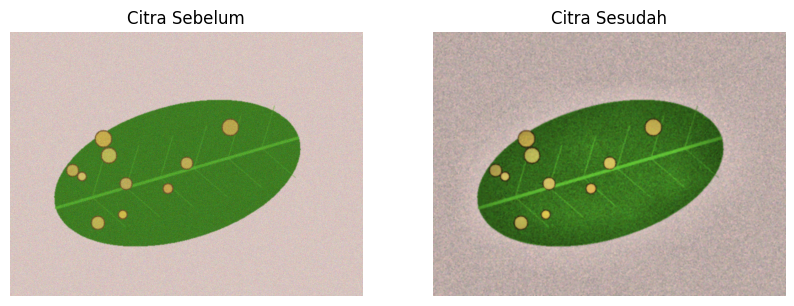

Ukuran sebelum: (480, 640, 3)
Ukuran sesudah: (480, 640, 3)


In [4]:

nama = "teh_041.png"

img = baca(os.path.join(CITRA, nama))
hasil = praproses(img, param)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Citra Sebelum")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
plt.title("Citra Sesudah")
plt.axis("off")

plt.show()

print("Ukuran sebelum:", img.shape)
print("Ukuran sesudah:", hasil.shape)


In [5]:

KANAL = 2  # 0 = B, 1 = G, 2 = R

NAMA_KANAL = ["B", "G", "R"]

print("Kanal yang digunakan:", NAMA_KANAL[KANAL])


Kanal yang digunakan: R


In [6]:

def baca_mask(path, ukuran):
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise FileNotFoundError(path)

    return cv2.resize(
        mask,
        (ukuran[1], ukuran[0]),
        interpolation=cv2.INTER_NEAREST
    )


def hitung_kb(img, md, mb):
    daun = md > 0
    bercak = (mb > 0) & daun
    sehat = daun & (mb == 0)

    if not np.any(bercak) or not np.any(sehat):
        return np.nan

    nilai_bercak = img[bercak]
    nilai_sehat = img[sehat]

    rata_bercak = np.mean(nilai_bercak)
    rata_sehat = np.mean(nilai_sehat)
    std_sehat = np.std(nilai_sehat)

    if std_sehat == 0:
        return np.nan

    return abs(rata_bercak - rata_sehat) / std_sehat


In [7]:

baris = []

data_bercak = label[label["kelas"] != "sehat"]

for _, d in data_bercak.iterrows():

    nama = d["nama_file"]

    img = baca(os.path.join(CITRA, nama))

    md = cv2.imread(
        os.path.join(MASK_DAUN, nama), 0
    )

    mb = cv2.imread(
        os.path.join(MASK_BERCAK, nama), 0
    )

    if img is None or md is None or mb is None:
        print("Data tidak ditemukan:", nama)
        continue

    hasil = praproses(img, param)

    # KB sebelum
    kb_sebelum = hitung_kb(
        img[:, :, KANAL], md, mb
    )

    # Sesuaikan mask dengan ukuran hasil
    md_hasil = baca_mask(
        os.path.join(MASK_DAUN, nama), hasil.shape[:2]
    )
    mb_hasil = baca_mask(
        os.path.join(MASK_BERCAK, nama), hasil.shape[:2]
    )

    kb_sesudah = hitung_kb(
        hasil[:, :, KANAL], md_hasil, mb_hasil
    )

    baris.append({
        "nama_file": nama,
        "kondisi": d["kondisi_cahaya"],
        "KB_sebelum": kb_sebelum,
        "KB_sesudah": kb_sesudah
    })

evaluasi = pd.DataFrame(baris)

evaluasi.to_csv(
    os.path.join(HASIL, "b5_evaluasi_40_citra.csv"),
    index=False
)

print("Jumlah citra diuji:", len(evaluasi))
evaluasi.head()


Jumlah citra diuji: 40


,nama_file,kondisi,KB_sebelum,KB_sesudah
0,teh_021.png,normal,7.290658,9.194758
1,teh_022.png,gelap,6.613090,12.619839
2,teh_023.png,terang,8.645564,7.968296
3,teh_024.png,kontras_rendah,2.316455,3.513899
4,teh_025.png,bayangan,4.211578,7.286402


In [8]:

ringkasan = evaluasi.groupby("kondisi").agg(
    KB_sebelum=("KB_sebelum", "mean"),
    KB_sesudah=("KB_sesudah", "mean")
).reset_index()

ringkasan["Perubahan (%)"] = (
    (ringkasan["KB_sesudah"] - ringkasan["KB_sebelum"])
    / ringkasan["KB_sebelum"].replace(0, np.nan)
) * 100

ringkasan["KB_sebelum"] = ringkasan["KB_sebelum"].round(2)
ringkasan["KB_sesudah"] = ringkasan["KB_sesudah"].round(2)
ringkasan["Perubahan (%)"] = ringkasan["Perubahan (%)"].round(2)

print(ringkasan)

ringkasan.to_csv(
    os.path.join(HASIL, "b5_tabel_12.csv"),
    index=False
)


          kondisi  KB_sebelum  KB_sesudah  Perubahan (%)
0        bayangan        5.00        8.15          62.88
1           gelap       11.01       18.62          69.20
2  kontras_rendah        3.69        4.91          33.34
3          normal        9.11       11.64          27.76
4          terang        6.30        6.16          -2.35


In [9]:

data_sehat = label[label["kelas"] == "sehat"]

hasil_sehat = []

for _, d in data_sehat.iterrows():

    nama = d["nama_file"]

    img = baca(os.path.join(CITRA, nama))
    hasil = praproses(img, param)

    md = baca_mask(
        os.path.join(MASK_DAUN, nama),
        img.shape[:2]
    )

    md_hasil = baca_mask(
        os.path.join(MASK_DAUN, nama),
        hasil.shape[:2]
    )

    std_sebelum = np.std(
        img[:, :, KANAL][md > 0]
    )

    std_sesudah = np.std(
        hasil[:, :, KANAL][md_hasil > 0]
    )

    hasil_sehat.append({
        "nama_file": nama,
        "kondisi": d["kondisi_cahaya"],
        "std_sebelum": std_sebelum,
        "std_sesudah": std_sesudah
    })

evaluasi_sehat = pd.DataFrame(hasil_sehat)

evaluasi_sehat.to_csv(
    os.path.join(HASIL, "b5_uji_citra_sehat.csv"),
    index=False
)

print(evaluasi_sehat.head())


     nama_file         kondisi  std_sebelum  std_sesudah
0  teh_001.png          normal    14.521167    10.607724
1  teh_002.png           gelap     9.127318     5.717475
2  teh_003.png          terang     9.137942    11.736254
3  teh_004.png  kontras_rendah    13.085723    10.877692
4  teh_005.png        bayangan    13.175204    10.430519


In [10]:

ringkasan_sehat = evaluasi_sehat.groupby("kondisi").agg(
    std_sebelum=("std_sebelum", "mean"),
    std_sesudah=("std_sesudah", "mean")
).round(2).reset_index()

print(ringkasan_sehat)

ringkasan_sehat.to_csv(
    os.path.join(HASIL, "b5_ringkasan_citra_sehat.csv"),
    index=False
)


          kondisi  std_sebelum  std_sesudah
0        bayangan        12.87        10.24
1           gelap         8.18         5.70
2  kontras_rendah        12.85        11.47
3          normal        11.93         9.73
4          terang         9.97        11.51


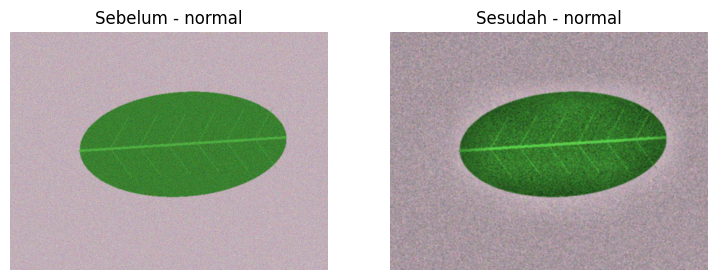

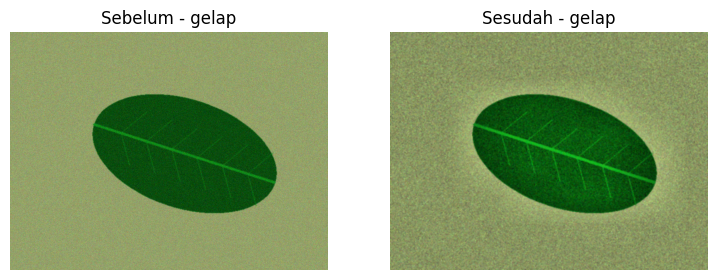

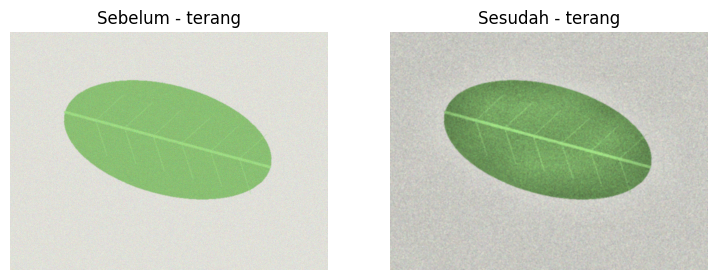

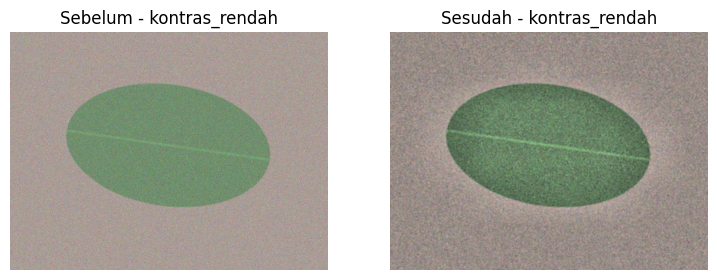

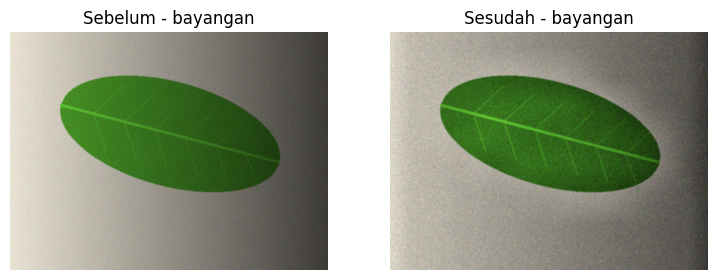

In [11]:

kondisi_unik = data_sehat["kondisi_cahaya"].unique()

for kondisi in kondisi_unik:

    d = data_sehat[
        data_sehat["kondisi_cahaya"] == kondisi
    ].iloc[0]

    nama = d["nama_file"]

    img = baca(os.path.join(CITRA, nama))
    hasil = praproses(img, param)

    plt.figure(figsize=(9, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Sebelum - " + kondisi)
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
    plt.title("Sesudah - " + kondisi)
    plt.axis("off")

    plt.show()


In [12]:

simpan_param(
    param,
    os.path.join(HASIL, "param_praproses.json")
)

print("Parameter final tersimpan.")


Parameter final tersimpan.
